## Customer Churn Prediction in Telcom

1. Importing Libraries
2. Data Loading and Inspection
3. Data Preprocessing
4. Feature Engineering
5. Model Evaluation and Performance Metrics

### 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### 2. Data Loading and Inspection

In [2]:
df = pd.read_csv('data/customer_churn.csv')
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

### 3. Data Preprocessing

In [4]:
print(df['TotalCharges'].dtype)
print(df['TotalCharges'].describe())

str
count     7043
unique    6531
top       20.2
freq        11
Name: TotalCharges, dtype: object


We checked the TotalCharges data type and stats, and looked for potential text formatting issues.

In [5]:
df[df['TotalCharges'].str.strip() == ""]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [6]:
df['TotalCharges'] = df['TotalCharges'].astype(str).str.strip()
df['TotalCharges'].replace({"":np.nan}, inplace=True)
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

C:\Users\dorot\AppData\Local\Temp\ipykernel_16408\401372411.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges'].replace({"":np.nan}, inplace=True)


In [7]:
df.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df[df.duplicated()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
1491,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1739,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes
1932,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
2713,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
2892,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.45,20.45,No
3301,Female,1,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,Yes
3754,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
4098,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.20,20.20,Yes


In [10]:
df=df.drop_duplicates().reset_index(drop=True)

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7010.000000,7010.000000,7010.000000,7010.000000
mean,0.162767,32.520399,64.888666,2290.353388
std,0.369180,24.520441,30.064769,2266.820832
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.750000,408.312500
50%,0.000000,29.000000,70.400000,1403.875000
75%,0.000000,56.000000,89.900000,3807.837500
max,1.000000,72.000000,118.750000,8684.800000


We checked summary statistics and found that tenure, MonthlyCharges, and TotalCharges look evenly distributed. We notice
that SeniorCitizen is binary (0 or 1), acting like a category rather than a continuous number.


In [12]:
df.describe(include='object')

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010,7010
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3535,3617,4911,6330,3363,3090,3489,3079,3086,3464,2801,2773,3853,4158,2359,5153


In [13]:
cat_cols = df.select_dtypes(include='str').columns
for col in cat_cols:
    print(f"Column {col}: uniqe values: {df[col].unique()}")

Column gender: uniqe values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Column Partner: uniqe values: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Column Dependents: uniqe values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Column PhoneService: uniqe values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
Column MultipleLines: uniqe values: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
Column InternetService: uniqe values: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
Column OnlineSecurity: uniqe values: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Column OnlineBackup: uniqe values: <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
Column DeviceProtection: uniqe values: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Column TechSupport: uniqe values: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Column StreamingTV: un

In [14]:
def plot_hist(col):
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df,x=col,hue='Churn',fill=True)
    plt.show()

In [15]:
def plot_count(col):
    plt.figure(figsize=(6,4))
    sns.countplot(data=df,x=col,hue='Churn')
    plt.show()

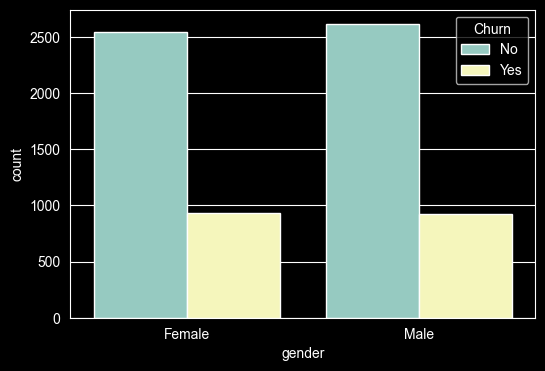

In [16]:
plot_count('gender')

The plot shows almost no difference in churn between genders. We will verify this with Cramér's V test before deciding whether to drop the column.

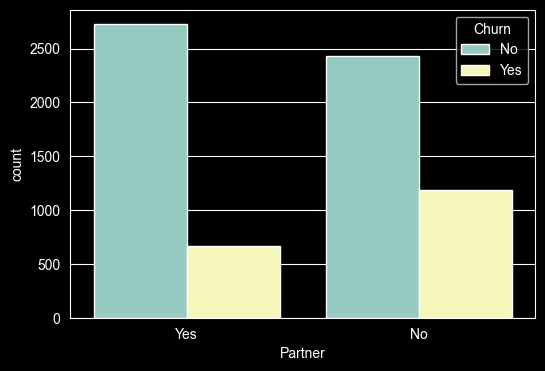

In [17]:
plot_count('Partner')

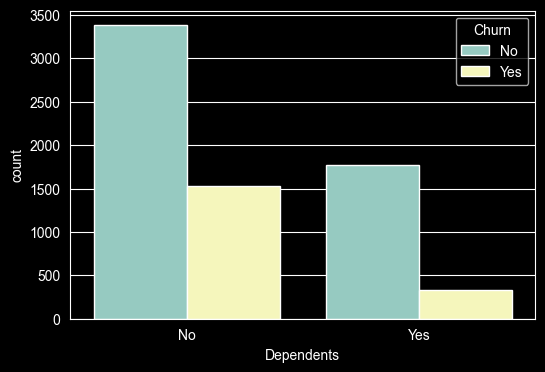

In [18]:
plot_count('Dependents')

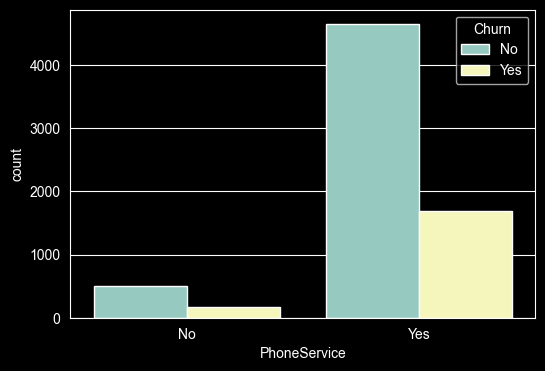

In [19]:
plot_count('PhoneService')

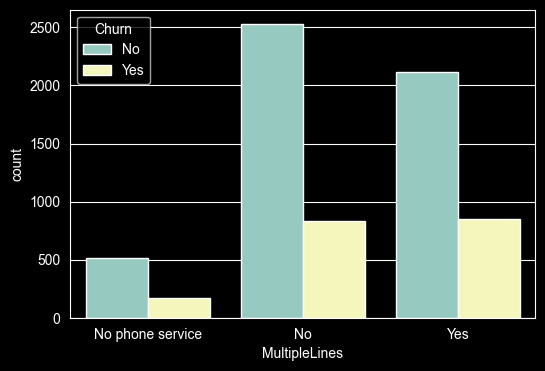

In [20]:
plot_count('MultipleLines')

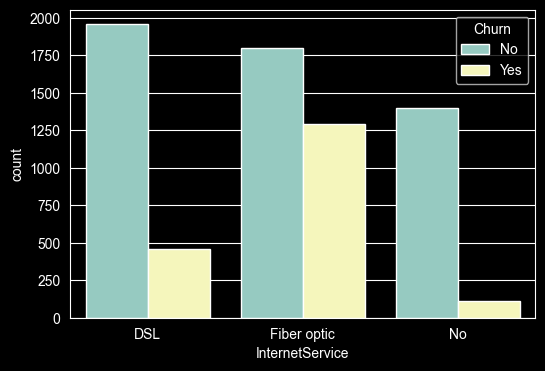

In [21]:
plot_count('InternetService')

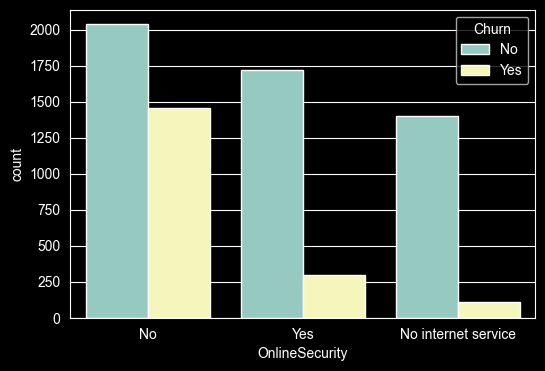

In [22]:
plot_count('OnlineSecurity')

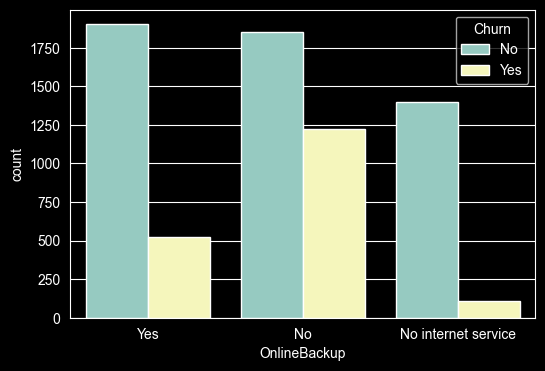

In [23]:
plot_count('OnlineBackup')

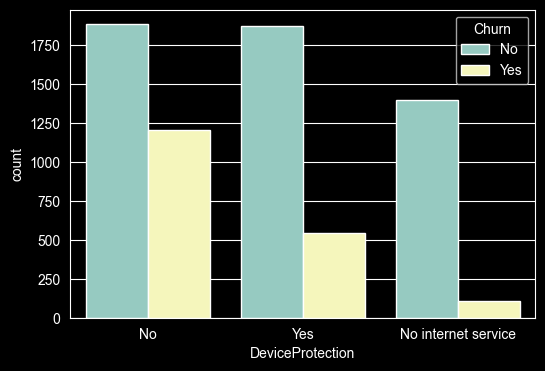

In [24]:
plot_count('DeviceProtection')

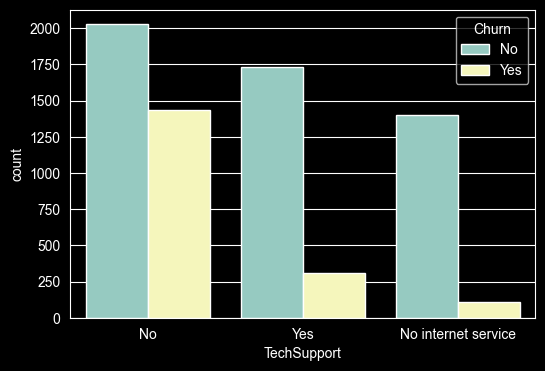

In [25]:
plot_count('TechSupport')

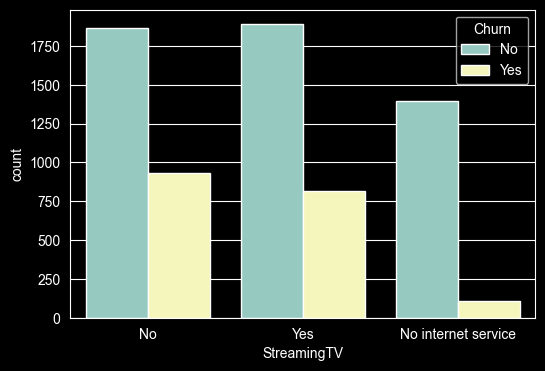

In [26]:
plot_count('StreamingTV')

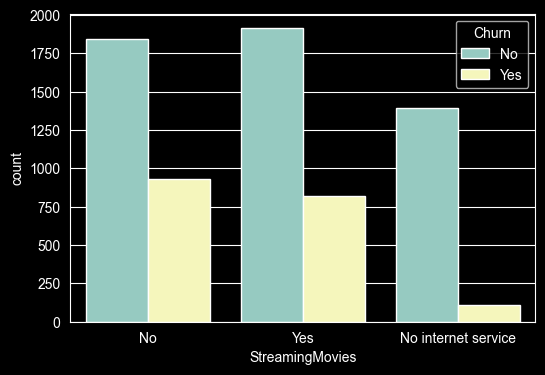

In [27]:
plot_count('StreamingMovies')

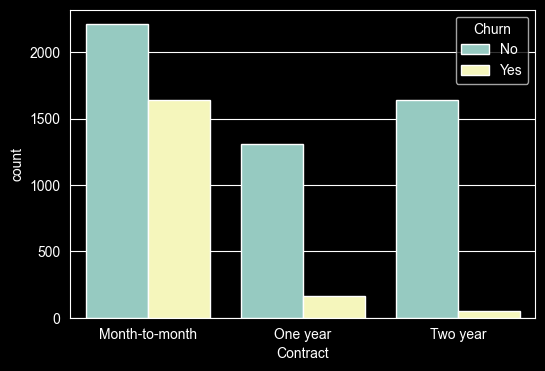

In [28]:
plot_count('Contract')

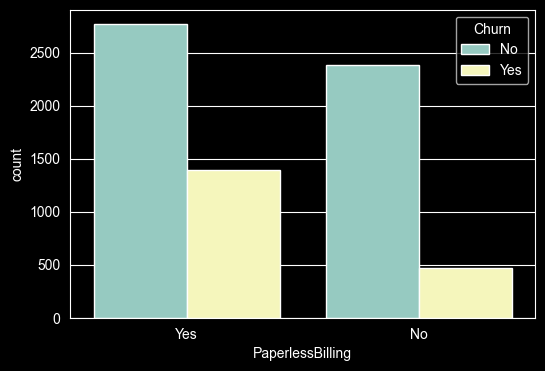

In [29]:
plot_count('PaperlessBilling')

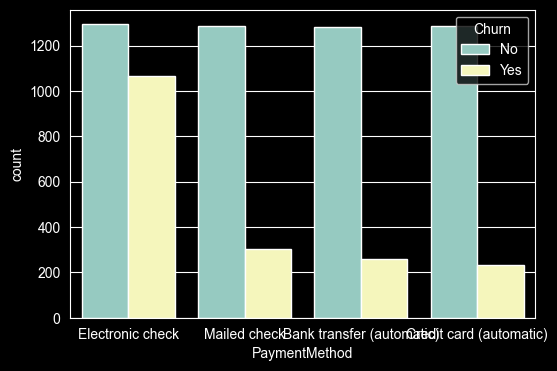

In [30]:
plot_count('PaymentMethod')

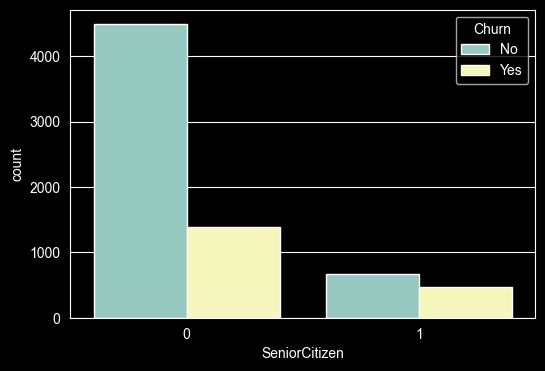

In [31]:
plot_count('SeniorCitizen')

Visual inspection shows potential differences across categories, but we will use Cramér's V test to statistically verify if we should drop those columns.

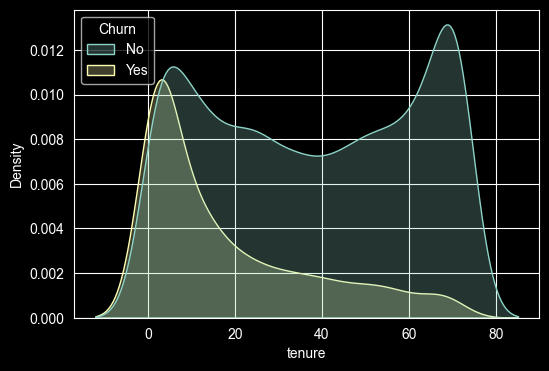

In [32]:
plot_hist('tenure')

Shorter tenure values show a much higher density for churned customers, indicating that new customers are more likely to leave.

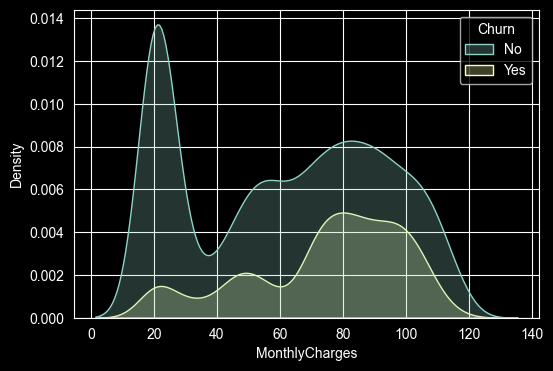

In [33]:
plot_hist('MonthlyCharges')

Higher monthly charges show an increased concentration of churned customers, suggesting that higher pricing correlates with higher churn.

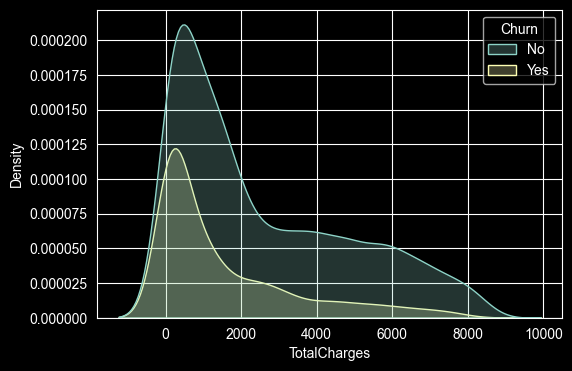

In [34]:
plot_hist('TotalCharges')

Lower total charges exhibit a higher density for churned users, heavily reflecting the impact of shorter customer lifecycles.

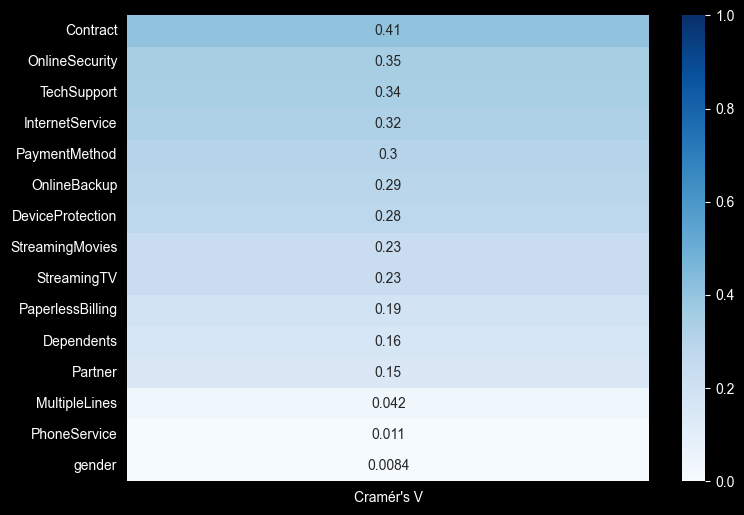

In [35]:
from scipy.stats import chi2_contingency
cat_cols = df.select_dtypes(include=['object', 'category']).columns.drop('Churn', errors='ignore')
results = {}

for col in cat_cols:
    table = pd.crosstab(df[col], df['Churn'])
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    k = min(table.shape[0] - 1, table.shape[1] - 1)

    results[col] = np.sqrt(chi2 / (n * k)) if k > 0 and n > 0 else np.nan

cramers_v = pd.Series(results).sort_values(ascending=False)

plt.figure(figsize=(8, max(5, len(cramers_v) * 0.35)))
sns.heatmap(cramers_v.to_frame(name="Cramér's V"),annot=True,cmap='Blues',vmin=0,vmax=1)
plt.tight_layout()
plt.show()

Features like Contract, OnlineSecurity, and TechSupport show the strongest association with churn, while variables at the bottom like gender, PhoneService, and MultipleLines have near-zero association, confirming we can safely drop them.

In [36]:
df.drop(columns=['MultipleLines','PhoneService','gender'],inplace=True)

In [37]:
yes_no_map={'Yes':1,'No':0}
yes_no_col=['Partner','Churn']
for col in yes_no_col:
    df[col]=df[col].map(yes_no_map)

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7010 entries, 0 to 7009
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7010 non-null   int64  
 1   Partner           7010 non-null   int64  
 2   Dependents        7010 non-null   str    
 3   tenure            7010 non-null   int64  
 4   InternetService   7010 non-null   str    
 5   OnlineSecurity    7010 non-null   str    
 6   OnlineBackup      7010 non-null   str    
 7   DeviceProtection  7010 non-null   str    
 8   TechSupport       7010 non-null   str    
 9   StreamingTV       7010 non-null   str    
 10  StreamingMovies   7010 non-null   str    
 11  Contract          7010 non-null   str    
 12  PaperlessBilling  7010 non-null   str    
 13  PaymentMethod     7010 non-null   str    
 14  MonthlyCharges    7010 non-null   float64
 15  TotalCharges      7010 non-null   float64
 16  Churn             7010 non-null   int64  
dtypes: flo

In [39]:
df['Churn'].value_counts()

Churn
0    5153
1    1857
Name: count, dtype: int64

### 4. Feature Engineering

In [40]:
X=df.drop('Churn',axis=1)
y=df['Churn']

In [41]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_transformer = Pipeline(steps=[("scaler", StandardScaler()),])

categorical_transformer = Pipeline(steps=[("onehot",OneHotEncoder(handle_unknown="ignore", drop="first"))])

preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)])

C:\Users\dorot\AppData\Local\Temp\ipykernel_16408\3990533001.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [42]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=7,stratify=y)

In [43]:
rf = RandomForestClassifier(random_state=42,class_weight="balanced")
param_grid = {
    "classifier__n_estimators": [50, 100, 150, 200, 300],
    "classifier__max_depth": [2, 4, 6, 8, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
}

pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier",RandomForestClassifier(class_weight="balanced", random_state=42),),])

grid_search = GridSearchCV(estimator=pipeline,param_grid=param_grid,cv=5,scoring='roc_auc',n_jobs=-1,verbose=1,)
grid_search.fit(X_train, y_train)

print('Best Parameters:', grid_search.best_params_)
print('Best Cross-Validation Score:', grid_search.best_score_)

Best Parameters: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}
Best Cross-Validation Score: 0.846347443177019


In [49]:
best_model = grid_search.best_estimator_
test_score = best_model.score(X_test, y_test)
print(f'Test Set Accuracy: {test_score:.4f}')

Test Set Accuracy: 0.7725


### 5. Model Evaluation and Performance Metrics

In [50]:
y_pred = best_model.predict(X_test)

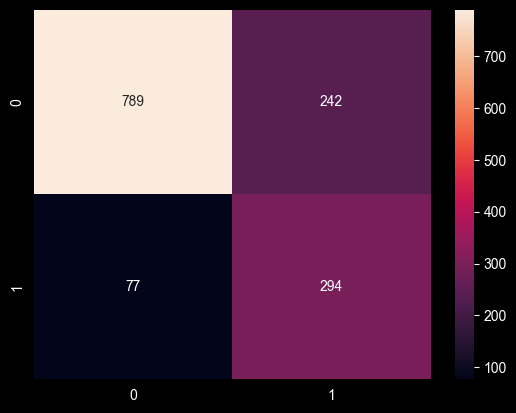

In [51]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt='g')
plt.show()

In [52]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred)*100}%")
print(f"Recall Score: {recall_score(y_test, y_pred)*100}%")
print(f"Precision Score: {precision_score(y_test, y_pred)*100}%")
print(f"F1 Score: {f1_score(y_test, y_pred)*100}%")

Accuracy Score: 77.24679029957204%
Recall Score: 79.24528301886792%
Precision Score: 54.850746268656714%
F1 Score: 64.82910694597575%


- **Accuracy (77.25%):** Out of all customers tested, the model made the correct prediction (whether they stayed or left) 77 out of every 100 times.
- **Recall (79.25%):** Out of all the customers who actually churned, the model successfully caught 79 out of every 100 of them.
- **Precision (54.85%):** Out of all the customers the model warned were going to churn, only about 55 out of every 100 actually left (the rest were false alarms).
- **F1-Score (64.83%):** This is the overall balance between your precision and recall, showing a solid middle ground for catching churners without making too many false accusations.

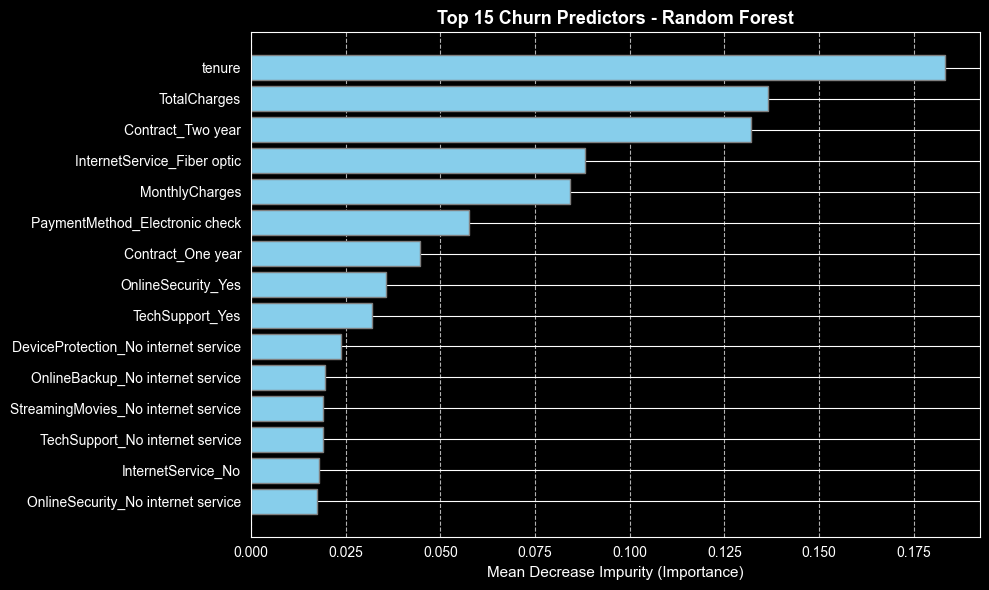

In [48]:
cat_encoder = (grid_search.best_estimator_.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"])
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

all_feature_names = numeric_features + encoded_cat_features
importances = grid_search.best_estimator_.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({"Feature": all_feature_names, "Importance": importances}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 6))
top_features = feature_importance_df.tail(15)  # Select top 15 features

plt.barh(top_features["Feature"],top_features["Importance"],color="skyblue",edgecolor="grey",)
plt.xlabel("Mean Decrease Impurity (Importance)", fontsize=11)
plt.title("Top 15 Churn Predictors - Random Forest", fontsize=13, weight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Tenure and TotalCharges are by far the most powerful indicators, meaning a customer's length of stay and overall investment heavily dictate whether they will leave. Having a Contract_Two_year ranks right behind charges, showing that long-term contracts are a massive deterrent against churn. Features like InternetService_Fiber_optic, MonthlyCharges, and PaymentMethod_Electronic check heavily influence the model's decisions, highlighting pricing pressure and specific payment methods as key risk factors.